# 1. Importo librerías de trabajo y cargo el dataset

In [ ]:
import utils.constantes as cte
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency

%matplotlib inline

In [2]:
df = pd.read_csv("../data/enfermedad_cardiovascular.csv")

df.head()

,edad,presion_sistolica,presion_diastolica,colesterol_total,colesterol_hdl,colesterol_ldl,trigliceridos,glucosa_ayunas,indice_masa_corporal,frecuencia_cardiaca_reposo,...,hemoglobina_glicosilada,fumador_actual,hipertension_previa,diabetes_mellitus,tratamiento_estatinas,uso_antihipertensivos,tipo_alimentacion,nivel_actividad,antecedentes_familiares_tipo,riesgo_cardiovascular
0,57.4,192.0,78.9,371.24,62.6,149.1,245.6,NaN,30.4,95.1,...,5.41,1,1,1,0,1,Mediterránea,Moderadamente activo,Ninguno,2
1,51.7,131.2,80.0,270.20,35.4,NaN,173.8,137.5,29.7,85.3,...,6.11,0,1,0,1,1,Baja en carbohidratos,Ligeramente activo,Ambos,1
2,56.7,127.1,92.5,202.30,47.7,134.1,60.9,157.4,29.4,87.5,...,6.52,1,1,0,0,1,Baja en carbohidratos,Sedentario,Ninguno,2
3,54.9,112.8,97.9,179.20,53.9,137.9,174.4,92.0,28.6,47.4,...,4.06,0,1,0,0,1,Occidental,Ligeramente activo,Paterno,0
4,47.2,115.1,97.0,242.20,56.5,159.2,195.7,63.5,18.5,69.0,...,4.63,0,0,0,0,0,Occidental,Muy activo,Ninguno,0


# 2. Observo las columnas 

Este análisis ya lo habían hecho mis compañeros pero me sirve a mí para situarme y dividir los grupos de variables.

In [15]:
df.info()
print(df.isna().sum().sum(), "nulos")
print(df.duplicated().sum(), "duplicados")

<class 'pandas.DataFrame'>
RangeIndex: 2254 entries, 0 to 2253
Data columns (total 28 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   edad                          2254 non-null   float64
 1   presion_sistolica             2254 non-null   float64
 2   presion_diastolica            2254 non-null   float64
 3   colesterol_total              2254 non-null   float64
 4   colesterol_hdl                2254 non-null   float64
 5   colesterol_ldl                2119 non-null   float64
 6   trigliceridos                 2254 non-null   float64
 7   glucosa_ayunas                2142 non-null   float64
 8   indice_masa_corporal          2254 non-null   float64
 9   frecuencia_cardiaca_reposo    2254 non-null   float64
 10  horas_sueno_diarias           2074 non-null   float64
 11  consumo_alcohol_semanal       2254 non-null   float64
 12  anos_fumador                  2254 non-null   float64
 13  proteina_c_rea

# 3. Defino las variables según su tipo

In [ ]:
objetivo = "riesgo_cardiovascular"
binarias = ["fumador_actual", "hipertension_previa", "diabetes_mellitus",
            "tratamiento_estatinas", "uso_antihipertensivos"]
categoricas = ["tipo_alimentacion", "nivel_actividad", "antecedentes_familiares_tipo"]
numericas = [c for c in df.columns if c not in binarias + categoricas + [objetivo]]   # las 19 numéricas

## 3.1 Analizo la variable objetivo

Tenemos las siguientes categorías que están ordenadas (bajo < moderado < alto):

* 0 = Bajo riesgo
* 1 = Riesgo moderado
* 2 = Alto riesgo

Esto nos indica que estamos ante un problema de clasificación con 3 clases. Como es un caso clínico en el que clasificamos a un paciente según su riesgo cardiovascular, el error más grave es clasificar a un paciente de riesgo alto como de riesgo bajo: se iría a casa sin seguimiento. Ese error debe ser el que más se castigue, seguido de clasificar a un paciente de riesgo alto como de riesgo moderado. Por eso la sensibilidad (recall) de la clase de riesgo alto va a ser una de las métricas más importantes:

$$
\text{Sensibilidad}=\frac{VP}{VP+FN}=\frac{VP}{P}
$$

Riesgo bajo: 1127 pacientes (50%)
Riesgo moderado: 676 pacientes (30%)
Riesgo alto: 451 pacientes (20%)
Pacientes sin clase: 0


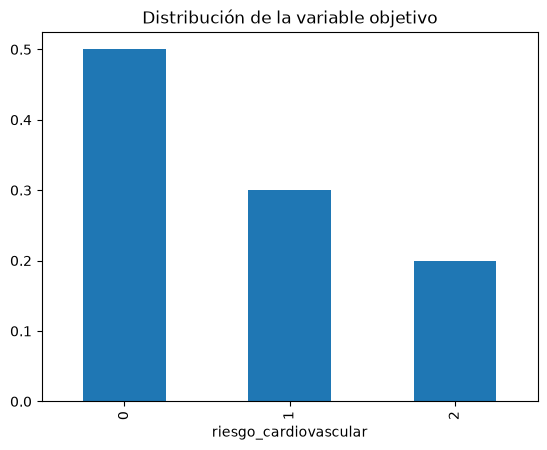

In [16]:
nombres = {0: "bajo", 1: "moderado", 2: "alto"}
for clase, n in df[objetivo].value_counts().sort_index().items():
    print(f"Riesgo {nombres[clase]}: {n} pacientes ({n / len(df):.0%})")
print(f"Pacientes sin clase: {df[objetivo].isna().sum()}")

df[objetivo].value_counts(normalize=True).sort_index().plot(kind="bar", title="Distribución de la variable objetivo")
plt.show()

El desbalanceo es moderado, viendo estas distribuciones esto implica que:

1. Un modelo que siempre clasificase como "riesgo bajo", ya nos daría un 50% de accuracy, lo cual es engañoso y por eso es importante el recall de la clase de riesgo alto.
2. Las particiones de train, test y validación cruzada deben ser estratificadas para mantener la proporción 50/30/20.

## 3.2 ¿Qué variables se relacionan más con el riesgo?



In [ ]:
corr_objetivo = (
    df[numericas]
    .corrwith(df[objetivo], method="spearman")   # una correlación por columna frente al objetivo
    .sort_values(key=abs, ascending=False)       # ordeno por fuerza, sin importar el signo
    .rename("rho_spearman")
)
corr_objetivo.round(3)


consumo_alcohol_semanal         0.388
hemoglobina_glicosilada         0.283
proteina_c_reactiva             0.282
acido_urico                     0.213
glucosa_ayunas                  0.210
frecuencia_ejercicio_semanal   -0.207
colesterol_hdl                 -0.200
indice_masa_corporal            0.196
clearance_creatinina           -0.184
edad                            0.159
anos_fumador                    0.151
perimetro_cintura               0.144
horas_sueno_diarias            -0.144
presion_diastolica              0.141
presion_sistolica               0.138
colesterol_ldl                  0.132
colesterol_total                0.101
trigliceridos                   0.099
frecuencia_cardiaca_reposo      0.084
Name: rho_spearman, dtype: float64

Utilizamos la correlación de Spearman porque la variable objetivo es ordinal, sin embargo, vemos que las correlaciones no son muy fuertes:

* El **consumo del alcohol** parece la variable *más correlacionada con un mayor riesgo cardiovascular*, pero tampoco es una variable con una correlación muy acusada

* Le siguen la hemoglobina, proteina c reactiva, el ácido úrico y la glucosa en ayunas.

* Vemos también variables con correlaciones negativas, lo que significa que son variables que se asocian a un menor riesgo cardiovascular como: la frecuencia del ejercicio semanal, el colesterol HDL (popularmente conocido como el bueno), el aclaramiento de la creatinina (que se relaciona con la función renal) y las horas de sueño. Lo que implica que a mayor valor en estas variables numéricas, menor riesgo cardiovascular.

De todos modos, tenemos que tener en mente que correlación no implica causalidad.

# 4. Variables categóricas y binarias

## 4.1 Variables categóricas

In [25]:
for col in categoricas:
    print(f"{col}: {df[col].unique()} categorías")
    print("-" * 40)
    print(df[col].value_counts(normalize=True).sort_index())


tipo_alimentacion: <StringArray>
['Mediterránea', 'Baja en carbohidratos', 'Occidental', 'Vegetariana']
Length: 4, dtype: str categorías
----------------------------------------
tipo_alimentacion
Baja en carbohidratos    0.154836
Mediterránea             0.313221
Occidental               0.390861
Vegetariana              0.141083
Name: proportion, dtype: float64
nivel_actividad: <StringArray>
['Moderadamente activo', 'Ligeramente activo', 'Sedentario', 'Muy activo']
Length: 4, dtype: str categorías
----------------------------------------
nivel_actividad
Ligeramente activo      0.308341
Moderadamente activo    0.249778
Muy activo              0.137090
Sedentario              0.304791
Name: proportion, dtype: float64
antecedentes_familiares_tipo: <StringArray>
['Ninguno', 'Ambos', 'Paterno', 'Materno']
Length: 4, dtype: str categorías
----------------------------------------
antecedentes_familiares_tipo
Ambos      0.083407
Materno    0.229370
Ninguno    0.475599
Paterno    0.211624
Name

**Hipótesis (conocimiento clínico):**

* `tipo_alimentacion`: se suele decir que la dieta mediterránea es la más saludable, así que espero menos riesgo cardiovascular en esos pacientes.
* `nivel_actividad`: más actividad física, menos riesgo; el sedentarismo, más riesgo.
* `antecedentes_familiares_tipo`: los antecedentes familiares probablemente expliquen un mayor riesgo cardiovascular.

In [27]:
orden = {
    "tipo_alimentacion": ["Mediterránea", "Vegetariana", "Baja en carbohidratos", "Occidental"],
    "nivel_actividad": ["Sedentario", "Ligeramente activo", "Moderadamente activo", "Muy activo"],
    "antecedentes_familiares_tipo": ["Ninguno", "Materno", "Paterno", "Ambos"],
}

for cat in categoricas:
    tabla = pd.crosstab(df[cat], df[objetivo], normalize="index").reindex(orden[cat]).round(2)
    tabla["pacientes"] = df[cat].value_counts()
    display(tabla)

riesgo_cardiovascular,0,1,2,pacientes
tipo_alimentacion,,,,
Mediterránea,0.64,0.24,0.12,706
Vegetariana,0.54,0.33,0.12,318
Baja en carbohidratos,0.50,0.30,0.20,349
Occidental,0.37,0.34,0.29,881


riesgo_cardiovascular,0,1,2,pacientes
nivel_actividad,,,,
Sedentario,0.34,0.35,0.31,687
Ligeramente activo,0.47,0.34,0.20,695
Moderadamente activo,0.62,0.25,0.13,563
Muy activo,0.72,0.19,0.08,309


riesgo_cardiovascular,0,1,2,pacientes
antecedentes_familiares_tipo,,,,
Ninguno,0.62,0.26,0.12,1072
Materno,0.46,0.32,0.22,517
Paterno,0.38,0.34,0.28,477
Ambos,0.24,0.36,0.40,188


**Conclusión.** Las tres hipótesis se cumplen:

* **Alimentación:** Tiene riesgo alto el 12 % de los pacientes con dieta mediterránea o vegetariana, frente al 29 % de los que siguen la occidental.

* **Actividad:** el riesgo alto baja de forma **ordenada**, del 31 % (sedentario) al 8 % (muy activo).

* **Antecedentes:** ninguno 12 %, materno 22 %, paterno 28 % y ambos 40 %.

**Implicación para el preprocesamiento:**

| Variable | Propuesta | Por qué |
|---|---|---|
| `tipo_alimentacion` | One-hot | Categorías sin orden |
| `nivel_actividad` | Ordinal (0 a 3, con el orden de arriba) | El riesgo sigue ese orden; con one-hot se perdería |
| `antecedentes_familiares_tipo` | Dos binarias: `antecedente_materno` y `antecedente_paterno` («Ambos» = 1 y 1) | Refleja lo que significa la variable y su efecto casi aditivo |

## 4.2 Variables binarias

**Hipótesis:** fumar, tener hipertensión o diabetes y estar en tratamiento deberían ir con más riesgo.

In [ ]:
# Al ser una variable binaria, que el valor sea 1 significa que el paciente tiene la condición,
#  por lo que a mayor valor medio, mayor riesgo. 
df.groupby(objetivo)[binarias].mean().T.round(2)

riesgo_cardiovascular,0,1,2
fumador_actual,0.19,0.30,0.39
hipertension_previa,0.28,0.38,0.56
diabetes_mellitus,0.15,0.27,0.34
tratamiento_estatinas,0.20,0.29,0.42
uso_antihipertensivos,0.25,0.40,0.53


La hipótesis se cumple, de hecho, el 56 % de los pacientes de riesgo alto tiene hipertensión previa y el 53 % toma antihipertensivos.

Al ser variables binarias, estas no necesitan ser codificadas.

# 5. Variables numéricas

Vamos a ver la mediana de cada varible numérica agrupada por riesgo para no vernos condicionados por outliers y los valores nulos que nos encontramos:

In [30]:
print("Mediana de cada variable numérica por clase de riesgo:")
display(df.groupby(objetivo)[numericas].median().T)

Mediana de cada variable numérica por clase de riesgo:


riesgo_cardiovascular,0,1,2
edad,54.90,57.800,59.60
presion_sistolica,127.70,129.100,135.60
presion_diastolica,80.30,82.950,85.00
colesterol_total,218.00,221.100,229.00
colesterol_hdl,50.60,45.650,42.20
colesterol_ldl,131.80,137.000,144.80
trigliceridos,163.80,171.500,180.20
glucosa_ayunas,99.60,104.600,112.60
indice_masa_corporal,26.80,28.500,30.20
frecuencia_cardiaca_reposo,72.30,73.700,75.30


In [34]:
print("Nulos por variable numérica:")
nulos = df[numericas].isna().sum()
nulos = nulos[nulos > 0].to_frame("nulos")
nulos["porcentaje"] = (nulos["nulos"] / len(df) * 100).round(2)
display(nulos)
print(f"Pacientes con al menos un nulo: {df.isna().any(axis=1).sum()} ({df.isna().any(axis=1).mean():.0%})")

Nulos por variable numérica:


,nulos,porcentaje
colesterol_ldl,135,5.99
glucosa_ayunas,112,4.97
horas_sueno_diarias,180,7.99
proteina_c_reactiva,157,6.97


Pacientes con al menos un nulo: 533 (24%)


**Conclusión.** Las medianas de las variables cambian de forma ordenada de riesgo bajo a alto: todas las numéricas aportan algo.

Hay nulos en cuatro variables (entre un 5 y un 8 % cada una), pero repartidos entre pacientes distintos: si eliminara las filas con algún nulo perdería **casi uno de cada cuatro pacientes**. Descarto eliminar filas y estudio cómo rellenar cada variable.

## 5.1 ¿Cómo podemos tratar los valores missing de LDL?

La fórmula de Friedewald nos permite calcular de forma aproximada el LDL:

$$
\text{LDL} \approx \text{Colesterol total} - \text{HDL} - \frac{\text{Triglicéridos}}{5}
$$
Vamos a comprobar si es una aproximación correcta para rellenar estos valores nulos:

In [ ]:
# 1) Comprobamos el error medio en los pacientes medidos si rellenamos los nulos con la fórmula de Friedewald,
#  y 2) si rellenamos con la mediana de LDL.
ldl_calculado = df["colesterol_total"] - df["colesterol_hdl"] - df["trigliceridos"] / 5
conocido = df["colesterol_ldl"].notna()
ldl_real = df.loc[conocido, "colesterol_ldl"]
print(f"Error medio con Friedewald: {(ldl_real - ldl_calculado[conocido]).abs().mean():.1f} mg/dL")
print(f"Error medio rellenando con la mediana: {(ldl_real - ldl_real.median()).abs().mean():.1f} mg/dL")

Error medio con Friedewald: 56.4 mg/dL
Error medio rellenando con la mediana: 29.5 mg/dL


In [40]:
# 2) Condiciones de validez de la fórmula y coherencia física (HDL + LDL no puede superar al CT)
print("TG >= 400 (Friedewald no aplica):", (df["trigliceridos"] >= 400).sum())
print("LDL calculado negativo:", (ldl_calculado < 0).sum())
print("HDL + LDL > colesterol total:", (df["colesterol_hdl"] + df["colesterol_ldl"] > df["colesterol_total"]).sum())

TG >= 400 (Friedewald no aplica): 54
LDL calculado negativo: 10
HDL + LDL > colesterol total: 559


Esto nos demuestra que con los datos que tenemos esta fórmula no aplica, vamos a comprobar entonces si existe alguna otra varible que nos ayude a predecir el LDL:

In [45]:
display(df[numericas + binarias].corrwith(df["colesterol_ldl"], method="spearman")
        .drop("colesterol_ldl").sort_values(key=abs, ascending=False).round(3))

hemoglobina_glicosilada         0.078
diabetes_mellitus               0.072
anos_fumador                    0.058
frecuencia_cardiaca_reposo      0.052
uso_antihipertensivos           0.047
hipertension_previa             0.046
tratamiento_estatinas           0.046
colesterol_hdl                 -0.043
consumo_alcohol_semanal         0.037
fumador_actual                  0.034
acido_urico                     0.031
glucosa_ayunas                 -0.027
colesterol_total                0.026
edad                            0.023
presion_sistolica              -0.022
presion_diastolica             -0.016
proteina_c_reactiva             0.012
perimetro_cintura               0.010
frecuencia_ejercicio_semanal   -0.010
horas_sueno_diarias            -0.009
clearance_creatinina            0.002
trigliceridos                  -0.002
indice_masa_corporal            0.002
dtype: float64

No tenemos ninguna correlación significativa con el resto de variables, comprobemos si estos valores faltan al azar o si tiene alguna relación con el riesgo:

In [ ]:
nulo_ldl = df["colesterol_ldl"].isna()
display(pd.crosstab(nulo_ldl, df[objetivo], normalize="index").round(2))
print("p-valor chi²:", round(chi2_contingency(pd.crosstab(nulo_ldl, df[objetivo])).pvalue, 3))

riesgo_cardiovascular,0,1,2
colesterol_ldl,,,
False,0.50,0.3,0.20
True,0.53,0.3,0.16


p-valor chi²: 0.518


**Conclusión:**

* Descartamos la aproximación de rellenar los valores missing de LDL a través de la fórmula de Friedewald, dado que no cumple los mínimos de coherencia ni tampoco otorga mejores resultados que otras aproximaciones.

* Probablemente, si pudiéramos contactar con el experto, sería interesante preguntarle cómo se tomaron esos datos, si se pueden recuperar o si existe una forma más correcta de tratar estos datos.

* Dada la escasa correlación de LDL con el resto de variables, previsiblemente un imputador multivariante tampoco mejoraría a la mediana, porque no tiene ninguna variable en la que apoyarse. Lo compruebo más adelante, comparando SimpleImputer y KNNImputer dentro del pipeline. Usar media o mediana, dependerá de si la variable es simétrica o no

* Tampoco vemos una relación entre el riesgo y que el valor sea faltante, sigue distribuciones similares a la variable objetivo.

Vamos a comprobar cuál sería la decisión para los valores missing de cada una de las variables numéricas que lo contienen:

## 5.2 Diagnóstico de las cuatro variables con nulos

Repito las mismas comprobaciones con cada una de las variables numéricas que tienen nulos, con una función reutilizable:

In [ ]:
def diagnostico_nulos(df, variable, objetivo, predictoras,
                      umbral_corr=0.3,  alfa=0.05):
    """Resume las tres comprobaciones que deciden cómo imputar `variable`.

    1. Si que falte el dato se relaciona con el riesgo (chi²) -> ¿añadir un indicador de nulo?
    2. Si alguna otra variable la acompaña (Spearman)          -> ¿imputación multivariante?
    3. Si es simétrica o tiene cola (asimetría)                -> ¿media o mediana?
    """
    nulo = df[variable].isna()              # True en los pacientes a los que les falta el dato
    clase_alta = df[objetivo].max()         # la clase de riesgo alto (2)

    # 1) Tabla "falta el dato (sí/no)" × clase de riesgo. Si el p-valor es bajo, la ausencia es informativa.
    tabla = pd.crosstab(nulo, df[objetivo])
    p_riesgo = chi2_contingency(tabla).pvalue
    reparto = pd.crosstab(nulo, df[objetivo], normalize="index")   # % de cada clase en cada grupo

    # 2) Spearman con el resto de predictoras (sin el objetivo: el imputador del Pipeline no ve la y).
    otras = [c for c in predictoras if c != variable]
    rho = df[otras].corrwith(df[variable], method="spearman")
    mejor = rho.abs().idxmax()              # la que más se relaciona, sea con signo + o −

    # 3) Asimetría con los valores observados: ≈ 0 simétrica, > 0 cola a la derecha, < 0 a la izquierda
    asimetria = df[variable].skew()

    # Decisión: primero miro si hay en qué apoyarse para una imputación multivariante; si no, media o mediana
    if abs(rho[mejor]) >= umbral_corr:
        metodo = "probar multivariante (KNN / Iterative)"
    else:
        metodo = "mediana"   # simétrica: media ≈ mediana; con cola: la mediana es más robusta

    return {
        "variable": variable,
        "% nulos": round(nulo.mean() * 100, 1),
        "% riesgo alto (nulos)": round(reparto.loc[True, clase_alta] * 100, 1),
        "% riesgo alto (con dato)": round(reparto.loc[False, clase_alta] * 100, 1),
        "p chi² riesgo": round(p_riesgo, 3),
        "indicador de nulo": "sí" if p_riesgo < alfa else "no",
        "más correlacionada": mejor,
        "rho": round(rho[mejor], 3),
        "asimetría": round(asimetria, 2),
        "media": round(df[variable].mean(), 2),
        "mediana": round(df[variable].median(), 2),
        "imputación propuesta": metodo,
    }

Debemos hacer varios matices a esta función `diagnostico_nulos`:

1. **El umbral de correlación (0,3) es arbitrario**, pero la decisión no depende de su valor exacto: en las cuatro variables la correlación más alta no llega a 0,09.

2. **La correlación por parejas no prueba que un imputador multivariante falle**, porque KNN combina todas las variables a la vez. Sí es un indicio, que compruebo en el apartado 5.3.

3. **Usar la media en unas variables y la mediana en otras obligaría a meter dos imputadores** sin ganar nada, porque en las variables simétricas media y mediana casi coinciden. Por eso propongo la mediana para todas.

In [47]:
con_nulos = [c for c in numericas if df[c].isna().any()]
resumen = pd.DataFrame([diagnostico_nulos(df, v, objetivo, numericas + binarias) for v in con_nulos])
resumen.set_index("variable").T


variable,colesterol_ldl,glucosa_ayunas,horas_sueno_diarias,proteina_c_reactiva
% nulos,6.0,5.0,8.0,7.0
% riesgo alto (nulos),16.3,27.7,19.4,16.6
% riesgo alto (con dato),20.2,19.6,20.1,20.3
p chi² riesgo,0.518,0.114,0.896,0.082
indicador de nulo,no,no,no,no
más correlacionada,hemoglobina_glicosilada,acido_urico,acido_urico,consumo_alcohol_semanal
rho,0.078,0.083,-0.067,0.098
asimetría,-0.05,0.12,0.02,1.59
media,135.64,104.11,6.75,2.35
mediana,135.5,103.75,6.8,1.79


* Como podemos ver en esta tabla, ninguna de las cuatro variables se relaciona con el resto (la correlación más alta no llega a 0,09), así que previsiblemente un KNN Imputer o un Iterative Imputer no nos aportaría mejores resultados.

* En ninguna variable el hecho de que falte el dato se relaciona con el riesgo (todos los p-valores del chi cuadrado están por encima de 0,05), así que no hace falta añadir un indicador de nulo.

* La media y la mediana son muy parecidas, salvo en `proteina_c_reactiva`, que tiene cola a la derecha. Ahí es más recomendable la mediana; en el resto, media y mediana darán resultados casi iguales.

## 5.3 Compruebo los imputadores con un experimento

Para no quedarme en un «previsiblemente», uso la técnica de la que vimos una la clase de Pepe: **escondo valores que conozco, los relleno con cada método y mido el error**.

* Uso los 1.721 pacientes sin ningún nulo, así conozco el valor real de cada hueco.
* En cada variable escondo al azar el mismo porcentaje de valores que le falta de verdad. Esconderlos al azar es coherente con el apartado 5.2: que falte el dato no se relaciona con el riesgo.
* Los imputadores ven solo las 19 numéricas, nunca el objetivo, igual que dentro del pipeline.
* Estandarizo antes de imputar, porque KNN mide distancias y, sin escalar, las dominarían el colesterol y los triglicéridos. A la media y la mediana no les afecta.
* Repito el sorteo 30 veces con la semilla del proyecto, porque un solo sorteo puede engañar.
* Comparo dos métodos univariantes (media y mediana) con dos multivariantes (KNN con 5 y con 25 vecinos, e Iterative), con el MAE y con el RMSE.

Ajusto los imputadores con todos los pacientes completos porque mido la calidad de la reconstrucción, no un modelo. En el pipeline, el imputador se ajustará solo con los datos de entrenamiento.

In [48]:
from sklearn.experimental import enable_iterative_imputer  # habilita IterativeImputer (sigue siendo experimental)
from sklearn.impute import SimpleImputer, KNNImputer, IterativeImputer

predictoras = numericas                                     # solo las 19 numéricas (sin binarias ni objetivo)
completos = df[predictoras].dropna().reset_index(drop=True)  # pacientes sin ningún nulo: conozco el valor real
pct_nulos = df[con_nulos].isna().mean()                      # oculto el mismo % que falta de verdad
print(f"Pacientes completos: {len(completos)}")
print("Valores que se ocultan en cada sorteo:", (pct_nulos * len(completos)).round().astype(int).to_dict())

imputadores = {
    "media": SimpleImputer(strategy="mean"),
    "mediana": SimpleImputer(strategy="median"),
    "KNN (k=5)": KNNImputer(n_neighbors=5),
    "KNN (k=25)": KNNImputer(n_neighbors=25),
    "Iterative": IterativeImputer(max_iter=10, random_state=cte.semilla),
}


Pacientes completos: 1721
Valores que se ocultan en cada sorteo: {'colesterol_ldl': 103, 'glucosa_ayunas': 86, 'horas_sueno_diarias': 137, 'proteina_c_reactiva': 120}


In [49]:
def un_sorteo(datos, pct_nulos, imputadores, rng):
    """Oculta valores al azar, los reconstruye con cada imputador y mide el error en los huecos."""
    # 1) Máscara: en cada variable marco al azar el mismo % de pacientes que tiene nulos en el dataset real
    mascara = pd.DataFrame(False, index=datos.index, columns=datos.columns)
    for variable, p in pct_nulos.items():
        filas = rng.choice(len(datos), size=round(p * len(datos)), replace=False)
        mascara.loc[filas, variable] = True
    huecos = datos.mask(mascara)                       # pongo NaN donde la máscara es True

    # 2) Estandarizo para que KNN no mida distancias dominadas por las variables de mayor escala
    #    (colesterol, triglicéridos). A la media y la mediana no les afecta: el cambio de escala se deshace al final.
    centro, escala = huecos.mean(), huecos.std()
    z = (huecos - centro) / escala

    # 3) Reconstruyo con cada imputador y comparo con el valor real solo en las celdas ocultas
    filas_resultado = []
    for nombre, imputador in imputadores.items():
        reconstruido = pd.DataFrame(imputador.fit_transform(z), columns=datos.columns) * escala + centro
        for variable in pct_nulos.index:
            ocultos = mascara[variable]
            error = reconstruido.loc[ocultos, variable] - datos.loc[ocultos, variable]
            filas_resultado.append({"método": nombre, "variable": variable,
                                    "MAE": error.abs().mean(),
                                    "RMSE": np.sqrt((error ** 2).mean())})
    return filas_resultado


In [50]:
n_sorteos = 30
rng = np.random.default_rng(cte.semilla)   # un generador con la semilla del proyecto: 30 sorteos distintos pero reproducibles
resultados = pd.DataFrame([
    {**fila, "sorteo": i}
    for i in range(n_sorteos)
    for fila in un_sorteo(completos, pct_nulos, imputadores, rng)
])

def media_desv(metrica):
    """Tabla variable × método con 'media ± desviación' de la métrica en los 30 sorteos."""
    r = resultados.groupby(["variable", "método"])[metrica].agg(["mean", "std"])
    texto = r["mean"].map("{:.2f}".format) + " ± " + r["std"].map("{:.2f}".format)
    return texto.unstack()[list(imputadores)]

display(media_desv("MAE"))
print("Referencia, desviación típica de cada variable:", completos[con_nulos].std().round(2).to_dict())


método,media,mediana,KNN (k=5),KNN (k=25),Iterative
variable,,,,,
colesterol_ldl,29.01 ± 1.95,29.03 ± 1.95,31.79 ± 2.32,29.50 ± 2.20,29.06 ± 1.97
glucosa_ayunas,20.28 ± 1.86,20.29 ± 1.86,21.87 ± 1.95,20.44 ± 2.01,20.08 ± 1.84
horas_sueno_diarias,1.26 ± 0.07,1.26 ± 0.07,1.36 ± 0.08,1.27 ± 0.07,1.26 ± 0.07
proteina_c_reactiva,1.56 ± 0.11,1.48 ± 0.14,1.67 ± 0.13,1.57 ± 0.11,1.55 ± 0.11


Referencia, desviación típica de cada variable: {'colesterol_ldl': 36.69, 'glucosa_ayunas': 25.25, 'horas_sueno_diarias': 1.58, 'proteina_c_reactiva': 2.01}


In [51]:
# Comparación por parejas: en cada sorteo todos los métodos rellenan los mismos huecos,
# así que puedo contar en qué % de sorteos cada método mejora a la mediana.
mae = resultados.pivot_table(index=["variable", "sorteo"], columns="método", values="MAE")
victorias = mae.drop(columns="mediana").lt(mae["mediana"], axis=0).groupby("variable").mean()
display((victorias * 100).round(0)[[m for m in imputadores if m != "mediana"]])


método,media,KNN (k=5),KNN (k=25),Iterative
variable,,,,
colesterol_ldl,73.0,3.0,33.0,47.0
glucosa_ayunas,50.0,3.0,27.0,73.0
horas_sueno_diarias,17.0,0.0,37.0,47.0
proteina_c_reactiva,0.0,0.0,3.0,3.0


In [52]:
display(media_desv("RMSE"))


método,media,mediana,KNN (k=5),KNN (k=25),Iterative
variable,,,,,
colesterol_ldl,35.73 ± 2.32,35.74 ± 2.32,39.18 ± 2.54,36.31 ± 2.60,35.74 ± 2.33
glucosa_ayunas,24.98 ± 2.16,24.99 ± 2.17,26.90 ± 2.35,25.17 ± 2.33,24.81 ± 2.18
horas_sueno_diarias,1.58 ± 0.07,1.58 ± 0.07,1.71 ± 0.09,1.59 ± 0.08,1.57 ± 0.08
proteina_c_reactiva,2.08 ± 0.20,2.17 ± 0.24,2.23 ± 0.21,2.10 ± 0.20,2.07 ± 0.21


**Conclusión.**

* **KNN con 5 vecinos es el peor en las cuatro variables**: pierde frente a la mediana en el 97-100 % de los sorteos. Con 25 vecinos se acerca a la media: cuantos más vecinos promedia, más se parece a rellenar con el promedio global. Es decir, los vecinos no aportan información.
* **Iterative empata con la media**: como las variables casi no se relacionan, sus regresiones acaban prediciendo la media. Su única ventaja, en la glucosa, es de 0,2 mg/dL (20,08 frente a 20,29), muy por debajo de la variación entre sorteos (±1,8). No justifica un imputador experimental.
* **En `proteina_c_reactiva`, la elección entre media y mediana depende de la métrica.** Con el MAE gana la mediana (1,48 frente a 1,56, en todos los sorteos); con el RMSE gana la media (2,08 frente a 2,17). Es una propiedad matemática: entre los valores constantes, la mediana es la que minimiza el error absoluto, y la media, el cuadrático. Me quedo con el MAE porque está en las unidades de la variable y no lo dominan los pocos pacientes con la PCR muy alta.
* **En todos los métodos, el MAE es unas 0,8 veces la desviación típica**, que es lo que se espera al rellenar siempre con el centro de la distribución. Ningún método recupera el valor del paciente.

Esto confirma el apartado 5.2: la **mediana** es igual o mejor que las alternativas, es la más sencilla y no necesita escalado.

## 5.4 ¿Cambia la distribución al imputar?

Se nos ha insistido varias veces en clase que, si se imputa, hay que comparar los estadísticos de la distribución antes y después: si cambian, la imputación ha metido ruido.

In [55]:
con_mediana = pd.DataFrame(SimpleImputer(strategy="median").fit_transform(df[con_nulos]), columns=con_nulos)
pd.DataFrame({
    "media antes": df[con_nulos].mean(),
    "media después": con_mediana.mean(),
    "mediana antes": df[con_nulos].median(),
    "mediana después": con_mediana.median(),
    "desv. típica antes": df[con_nulos].std(),
    "desv. típica después": con_mediana.std(),
}).round(2)

,media antes,media después,mediana antes,mediana después,desv. típica antes,desv. típica después
colesterol_ldl,135.64,135.63,135.50,135.50,36.73,35.62
glucosa_ayunas,104.11,104.09,103.75,103.75,24.94,24.31
horas_sueno_diarias,6.75,6.75,6.80,6.80,1.58,1.52
proteina_c_reactiva,2.35,2.31,1.79,1.79,1.97,1.91


**Conclusión.** Con la mediana, la media y la mediana de cada variable apenas cambian, y la desviación típica baja poco. 

**Decisión para la siguiente fase** imputar las cuatro variables con `SimpleImputer(strategy="median")` **dentro del pipeline**, para que la mediana se calcule solo con los datos de entrenamiento de cada fold. Los apartados 5.1-5.4 justifican esta elección, así que en la Fase 3 no hace falta volver a comparar imputadores.

# 7. Conclusiones abiertas para la reunión

| Tema | Propuesta | Evidencia | Pregunta para el grupo |
|---|---|---|---|
| Métrica y particiones | Recall de la clase de riesgo alto como métrica crítica; particiones estratificadas | 3.1 | ¿Qué otras dos métricas usamos? |
| Codificación | One-hot en `tipo_alimentacion`, ordinal en `nivel_actividad` y dos binarias en `antecedentes_familiares_tipo` | 4.1 | ¿Probamos también one-hot en las tres? |
| Nulos | `SimpleImputer(strategy="median")` en las cuatro variables, dentro del pipeline; sin indicador de nulo | 5.1-5.4 | ¿De acuerdo en no volver a comparar imputadores en la Fase 3? |
| Eliminar filas con nulos | Descartado: perderíamos casi uno de cada cuatro pacientes | 5 | — |